In [1]:
import sys
from pathlib import Path

project_root = Path("/mnt/x/segmentation_cfos")
sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from src.data.io_utils import read_tif_image, convert_image_to_array

# Chemins
masks_patches = Path("/mnt/x/donnees/pachs_64_3classes/masks")
mask_files = sorted(masks_patches.glob("*.tif"))

print(f"Total patches masks: {len(mask_files)}")

Total patches masks: 19657


In [ ]:


class_counts = []

for i, mask_file in enumerate(mask_files):
    mask_sitk = read_tif_image(str(mask_file))
    mask = convert_image_to_array(mask_sitk)
    
    c0 = (mask == 0).sum()
    c1 = (mask == 1).sum()
    c2 = (mask == 2).sum()
    
    class_counts.append((c0, c1, c2))
    
    if (i + 1) % 5000 == 0:
        print(f"  Traité {i+1}/{len(mask_files)} patches")

class_counts = np.array(class_counts)
print(f" {len(class_counts)} patches analysés")

In [3]:
total_voxels = class_counts.sum()
total_c0 = class_counts[:, 0].sum()
total_c1 = class_counts[:, 1].sum()
total_c2 = class_counts[:, 2].sum()

print("=" * 50)
print("STATISTIQUES GLOBALES")
print("=" * 50)
print(f"Total patches: {len(class_counts)}")
print(f"Total voxels: {total_voxels:,}")
print()
print(f"Classe 0 (Fond):        {total_c0:>12,} voxels ({total_c0/total_voxels*100:.2f}%)")
print(f"Classe 1 (Neurones):    {total_c1:>12,} voxels ({total_c1/total_voxels*100:.4f}%)")
print(f"Classe 2 (Vaisseaux):   {total_c2:>12,} voxels ({total_c2/total_voxels*100:.4f}%)")
print()
print(f"Ratio Fond/Neurones:     {total_c0/total_c1:.1f}")
print(f"Ratio Fond/Vaisseaux:    {total_c0/total_c2:.1f}")
print(f"Ratio Neurones/Vaisseaux: {total_c1/total_c2:.1f}")

STATISTIQUES GLOBALES
Total patches: 19657
Total voxels: 5,152,964,608

Classe 0 (Fond):        5,116,858,539 voxels (99.30%)
Classe 1 (Neurones):       5,494,052 voxels (0.1066%)
Classe 2 (Vaisseaux):     30,612,017 voxels (0.5941%)

Ratio Fond/Neurones:     931.3
Ratio Fond/Vaisseaux:    167.2
Ratio Neurones/Vaisseaux: 0.2


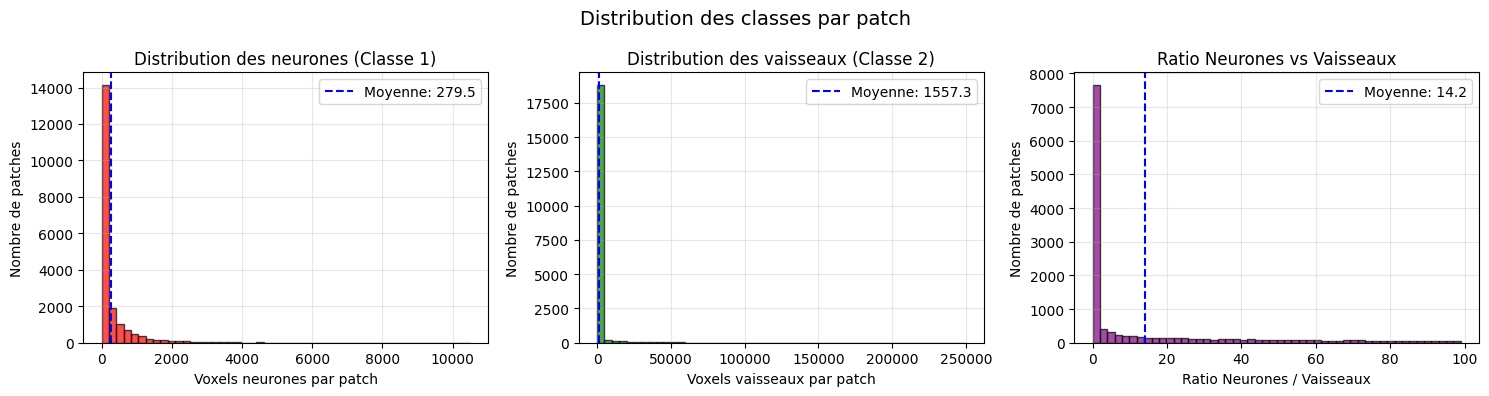

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))


neurons_per_patch = class_counts[:, 1]
neurons_nonzero = neurons_per_patch[neurons_per_patch > 0]

axes[0].hist(neurons_per_patch, bins=50, edgecolor='black', alpha=0.7, color='red')
axes[0].axvline(neurons_per_patch.mean(), color='blue', linestyle='--', 
                label=f'Moyenne: {neurons_per_patch.mean():.1f}')
axes[0].set_xlabel('Voxels neurones par patch')
axes[0].set_ylabel('Nombre de patches')
axes[0].set_title('Distribution des neurones (Classe 1)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)


vessels_per_patch = class_counts[:, 2]
vessels_nonzero = vessels_per_patch[vessels_per_patch > 0]

axes[1].hist(vessels_per_patch, bins=50, edgecolor='black', alpha=0.7, color='green')
axes[1].axvline(vessels_per_patch.mean(), color='blue', linestyle='--',
                label=f'Moyenne: {vessels_per_patch.mean():.1f}')
axes[1].set_xlabel('Voxels vaisseaux par patch')
axes[1].set_ylabel('Nombre de patches')
axes[1].set_title('Distribution des vaisseaux (Classe 2)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)


ratio_nv = neurons_per_patch / (vessels_per_patch + 1)  
ratio_nv = ratio_nv[ratio_nv < 100]  

axes[2].hist(ratio_nv, bins=50, edgecolor='black', alpha=0.7, color='purple')
axes[2].axvline(ratio_nv.mean(), color='blue', linestyle='--',
                label=f'Moyenne: {ratio_nv.mean():.1f}')
axes[2].set_xlabel('Ratio Neurones / Vaisseaux')
axes[2].set_ylabel('Nombre de patches')
axes[2].set_title('Ratio Neurones vs Vaisseaux')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle('Distribution des classes par patch', fontsize=14)
plt.tight_layout()
plt.show()

In [5]:
# Patch avec neurones uniquement, vaisseaux uniquement, les deux, aucun
has_neurons = neurons_per_patch > 0
has_vessels = vessels_per_patch > 0

only_neurons = (has_neurons) & (~has_vessels)
only_vessels = (~has_neurons) & (has_vessels)
both = has_neurons & has_vessels
none = (~has_neurons) & (~has_vessels)

print("=" * 50)
print("TYPES DE PATCHES")
print("=" * 50)
print(f"Patches avec neurones uniquement:    {only_neurons.sum():>6} ({only_neurons.sum()/len(class_counts)*100:.1f}%)")
print(f"Patches avec vaisseaux uniquement:   {only_vessels.sum():>6} ({only_vessels.sum()/len(class_counts)*100:.1f}%)")
print(f"Patches avec les deux:               {both.sum():>6} ({both.sum()/len(class_counts)*100:.1f}%)")
print(f"Patches vides (fond pur):            {none.sum():>6} ({none.sum()/len(class_counts)*100:.1f}%)")

TYPES DE PATCHES
Patches avec neurones uniquement:     11864 (60.4%)
Patches avec vaisseaux uniquement:     1006 (5.1%)
Patches avec les deux:                 1334 (6.8%)
Patches vides (fond pur):              5453 (27.7%)


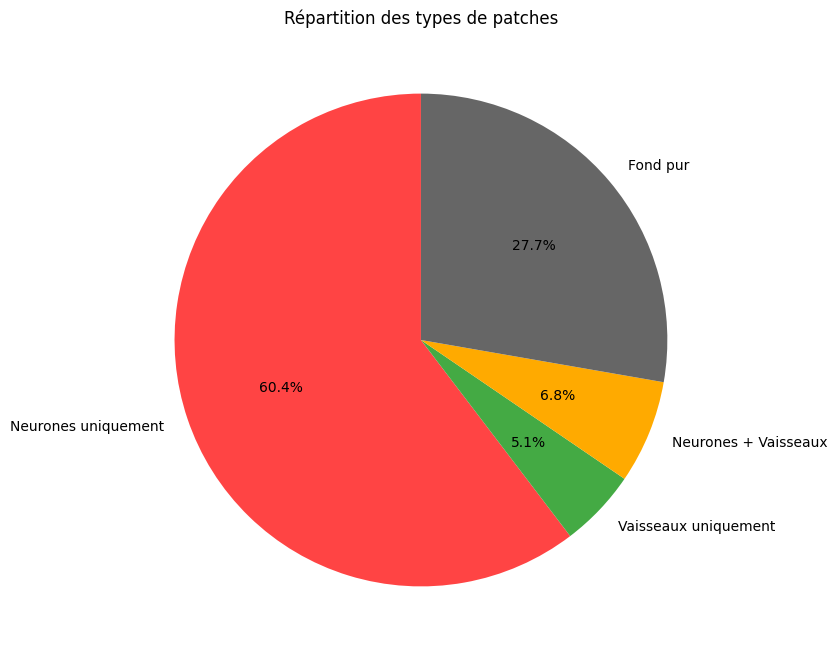

In [ ]:
labels = []
sizes = []
colors_patches = ['#FF4444', '#44AA44', '#FFAA00', '#666666']
explode = (0.05, 0.05, 0.05, 0)

if only_neurons.sum() > 0:
    labels.append('Neurones uniquement')
    sizes.append(only_neurons.sum())

if only_vessels.sum() > 0:
    labels.append('Vaisseaux uniquement')
    sizes.append(only_vessels.sum())

if both.sum() > 0:
    labels.append('Neurones + Vaisseaux')
    sizes.append(both.sum())

if none.sum() > 0:
    labels.append('Fond pur')
    sizes.append(none.sum())

plt.figure(figsize=(8, 8))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors_patches[:len(sizes)])
plt.title('Répartition des types de patches')
plt.show()

In [ ]:
print("=" * 50)
print("PATCHES EXTRÊMES")
print("=" * 50)

idx_max_neurons = np.argmax(neurons_per_patch)
idx_max_vessels = np.argmax(vessels_per_patch)
idx_min_neurons = np.argmin(neurons_per_patch[neurons_per_patch > 0]) if neurons_nonzero.size > 0 else None

print(f"Patch avec le plus de neurones:     {mask_files[idx_max_neurons].name}")
print(f"  Neurones: {neurons_per_patch[idx_max_neurons]}")
print(f"  Vaisseaux: {vessels_per_patch[idx_max_neurons]}")
print()
print(f"Patch avec le plus de vaisseaux:    {mask_files[idx_max_vessels].name}")
print(f"  Vaisseaux: {vessels_per_patch[idx_max_vessels]}")
print(f"  Neurones: {neurons_per_patch[idx_max_vessels]}")


plt.figure(figsize=(8, 8))
sizes_voxels = [total_c0, total_c1, total_c2]
labels_voxels = [f'Fond\n{total_c0/total_voxels*100:.2f}%', 
                 f'Neurones\n{total_c1/total_voxels*100:.4f}%',
                 f'Vaisseaux\n{total_c2/total_voxels*100:.4f}%']
colors_voxels = ['#333333', '#FF4444', '#44AA44']

plt.pie(sizes_voxels, labels=labels_voxels, autopct='%1.2f%%', startangle=90, colors=colors_voxels)
plt.title('Distribution des voxels par classe (tous patches)')
plt.show()

/tmp/ipykernel_262083/3670949141.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_to_plot, patch_artist=True, labels=['Neurones', 'Vaisseaux'])


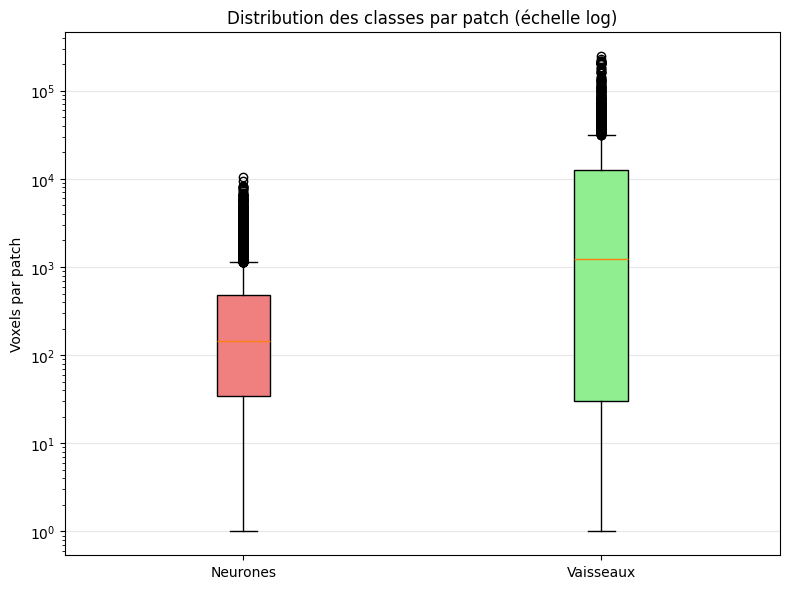

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))

data_to_plot = [
    neurons_per_patch[neurons_per_patch > 0],  
    vessels_per_patch[vessels_per_patch > 0],  
]

bp = ax.boxplot(data_to_plot, patch_artist=True, labels=['Neurones', 'Vaisseaux'])
bp['boxes'][0].set_facecolor('lightcoral')
bp['boxes'][1].set_facecolor('lightgreen')

ax.set_ylabel('Voxels par patch')
ax.set_yscale('log')
ax.set_title('Distribution des classes par patch (échelle log)')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()